# Task 3 — Image Inpainting with Stable Diffusion

**Assignment 6 · Image Generation by Stable Diffusion.** This notebook implements **Task 3**:
remove/replace a masked region of an image and fill it with prompt-driven content, while
keeping the rest of the image intact — then compare **different mask sizes and shapes**.

### The "Important Question": what are `x` and `y` for inpainting?

- **`x` (condition) = original image + a binary mask + a text prompt.**
- **`y` (target) = the completed image**: masked region filled per the prompt, unmasked region unchanged.

This is the first task where the **model itself changes**. Inpainting uses a dedicated
checkpoint whose UNet takes **9 input channels** (4 noisy-latent + 4 masked-image-latent +
1 downsampled mask), versus 4 channels for text-to-image / image-to-image. The mask and the
masked image are *concatenated to the UNet input*, so the network is explicitly told which
pixels to keep and which to synthesise — conditioning that img2img (initialisation only)
cannot express.

## 0. Environment

In [1]:
%pip install -q "diffusers>=0.27" "transformers>=4.38" accelerate peft datasets safetensors ftfy "torchmetrics[image]" scipy matplotlib pandas pillow tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Imports and configuration

Inpainting is inference-time (no training). We use the 9-channel SD-1.5 inpainting checkpoint.

In [2]:
import os, gc, json, math, random
from pathlib import Path
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageDraw
from tqdm.auto import tqdm

import torch
torch.backends.cuda.matmul.allow_tf32 = True

@dataclass
class CFG:
    inpaint_model_candidates: tuple = (
        "stable-diffusion-v1-5/stable-diffusion-inpainting",  # 9-channel UNet, ungated
        "botp/stable-diffusion-v1-5-inpainting",
    )
    resolution: int = 512
    img_dataset_candidates: tuple = (
        "sayakpaul/coco-30-val-2014", "zh-plus/tiny-imagenet", "nielsr/CelebA-faces",
    )
    use_local_images: bool = True       # use the assignment's "test images" folder
    local_images_dir: str = "test images"
    n_inputs: int = 10

    guidance_scale: float = 7.5
    num_inference_steps: int = 40
    seed: int = 42
    n_fid_images: int = 10
    quick_mode: bool = True

CFG = CFG()

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(CFG.seed)

device = "cuda" if torch.cuda.is_available() else "cpu"
use_cuda = device == "cuda"
if use_cuda and torch.cuda.is_bf16_supported(): weight_dtype = torch.bfloat16
elif use_cuda: weight_dtype = torch.float16
else: weight_dtype = torch.float32

OUT = Path("outputs_task3")
FIG, RES_DIR, GEN = OUT/"figures", OUT/"results", OUT/"generated"
for d in (FIG, RES_DIR, GEN): d.mkdir(parents=True, exist_ok=True)
print(f"device={device}  dtype={weight_dtype}")
print("config:", json.dumps(asdict(CFG), indent=2))

device=cuda  dtype=torch.bfloat16
config: {
  "inpaint_model_candidates": [
    "stable-diffusion-v1-5/stable-diffusion-inpainting",
    "botp/stable-diffusion-v1-5-inpainting"
  ],
  "resolution": 512,
  "img_dataset_candidates": [
    "sayakpaul/coco-30-val-2014",
    "zh-plus/tiny-imagenet",
    "nielsr/CelebA-faces"
  ],
  "use_local_images": true,
  "local_images_dir": "test images",
  "n_inputs": 10,
  "guidance_scale": 7.5,
  "num_inference_steps": 40,
  "seed": 42,
  "n_fid_images": 10,
  "quick_mode": true
}


## 2. The inpainting pipeline (report §2)

`StableDiffusionInpaintPipeline` loads the 9-channel inpainting UNet plus the shared VAE and
CLIP text encoder. All frozen — no training.

In [3]:
from diffusers import StableDiffusionInpaintPipeline, DPMSolverMultistepScheduler

pipe = None
for name in CFG.inpaint_model_candidates:
    try:
        pipe = StableDiffusionInpaintPipeline.from_pretrained(
            name, torch_dtype=weight_dtype, safety_checker=None, requires_safety_checker=False)
        print("loaded inpaint model:", name); break
    except Exception as e:
        print(f"[skip] {name}: {type(e).__name__}: {str(e).splitlines()[0][:70]}")
assert pipe is not None, "no inpainting checkpoint could be loaded"
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)
pipe = pipe.to(device)

def count_params(m): return sum(p.numel() for p in m.parameters())
in_ch = pipe.unet.config.in_channels
arch = pd.DataFrame([
    {"Component": "Text encoder (CLIP ViT-L/14)", "Params (M)": round(count_params(pipe.text_encoder)/1e6,2)},
    {"Component": "VAE (AutoencoderKL)",          "Params (M)": round(count_params(pipe.vae)/1e6,2)},
    {"Component": f"UNet (inpaint, {in_ch}-ch in)", "Params (M)": round(count_params(pipe.unet)/1e6,2)},
])
arch.loc[len(arch)] = ["TOTAL", round(arch["Params (M)"].sum(),2)]
arch.to_csv(RES_DIR/"architecture.csv", index=False)
print(f"UNet input channels = {in_ch}  (9 => inpaint-specific: 4 latent + 4 masked-image + 1 mask)")
arch

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

An error occurred while trying to fetch C:\Users\User\.cache\huggingface\hub\models--stable-diffusion-v1-5--stable-diffusion-inpainting\snapshots\8a4288a76071f7280aedbdb3253bdb9e9d5d84bb\vae: Error no file named diffusion_pytorch_model.safetensors found in directory C:\Users\User\.cache\huggingface\hub\models--stable-diffusion-v1-5--stable-diffusion-inpainting\snapshots\8a4288a76071f7280aedbdb3253bdb9e9d5d84bb\vae.


Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


An error occurred while trying to fetch C:\Users\User\.cache\huggingface\hub\models--stable-diffusion-v1-5--stable-diffusion-inpainting\snapshots\8a4288a76071f7280aedbdb3253bdb9e9d5d84bb\unet: Error no file named diffusion_pytorch_model.safetensors found in directory C:\Users\User\.cache\huggingface\hub\models--stable-diffusion-v1-5--stable-diffusion-inpainting\snapshots\8a4288a76071f7280aedbdb3253bdb9e9d5d84bb\unet.


Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


loaded inpaint model: stable-diffusion-v1-5/stable-diffusion-inpainting


UNet input channels = 9  (9 => inpaint-specific: 4 latent + 4 masked-image + 1 mask)


,Component,Params (M)
0,Text encoder (CLIP ViT-L/14),123.06
1,VAE (AutoencoderKL),83.65
2,"UNet (inpaint, 9-ch in)",859.54
3,TOTAL,1066.25


## 3. Input images (report §3)

At least 10 real photos (COCO validation), centre-cropped to a square.

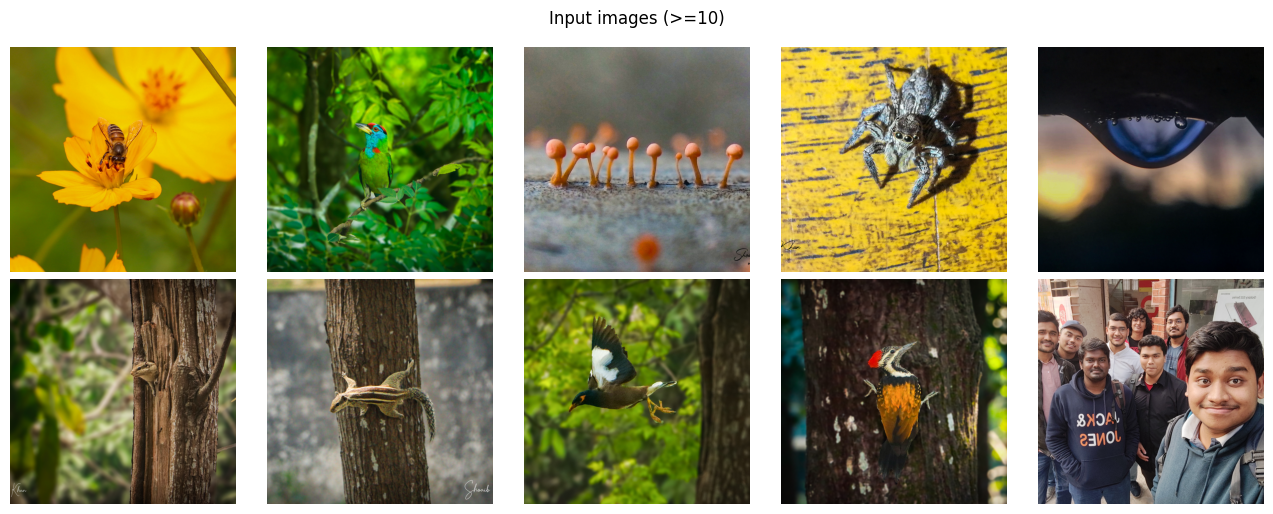

In [4]:
from datasets import load_dataset
from datasets.features import Image as HFImage

def prep_image(img):
    return ImageOps.fit(img.convert("RGB"), (CFG.resolution, CFG.resolution), Image.LANCZOS)

inputs = []
if CFG.use_local_images and Path(CFG.local_images_dir).exists():
    paths = sorted([p for p in Path(CFG.local_images_dir).iterdir()
                    if p.suffix.lower() in {".jpg",".jpeg",".png",".bmp",".webp"}])
    for p in paths[:CFG.n_inputs]:
        inputs.append({"image": prep_image(Image.open(p)), "caption": p.stem.replace("_"," ")})
else:
    ds = None
    for name in CFG.img_dataset_candidates:
        try: ds = load_dataset(name, split="train", streaming=True); src=name; break
        except Exception as e: print(f"[skip] {name}: {str(e).splitlines()[0][:60]}")
    assert ds is not None, "no image dataset could be loaded"
    feats = ds.features
    img_col = next((c for c,f in feats.items() if isinstance(f,HFImage)), "image")
    cap_col = next((c for c in ["caption","text","name"] if c in feats), None)
    for ex in ds:
        cap = ex.get(cap_col) if cap_col else None
        inputs.append({"image": prep_image(ex[img_col]), "caption": cap if isinstance(cap,str) else "a photo"})
        if len(inputs) >= CFG.n_inputs: break
    print(f"Loaded {len(inputs)} images from {src}")

def grid(images, titles=None, ncols=5, fs=2.6, suptitle=None, fname=None):
    n=len(images); ncols=min(ncols,n); nrows=math.ceil(n/ncols)
    fig,axes=plt.subplots(nrows,ncols,figsize=(fs*ncols,fs*nrows)); axes=np.array(axes).reshape(-1)
    for i,ax in enumerate(axes):
        if i<n:
            ax.imshow(images[i]); ax.axis("off")
            if titles: ax.set_title(titles[i], fontsize=8)
        else: ax.axis("off")
    if suptitle: fig.suptitle(suptitle)
    fig.tight_layout()
    if fname: fig.savefig(FIG/fname, dpi=130, bbox_inches="tight")
    plt.show()

grid([d["image"] for d in inputs], ncols=5, suptitle="Input images (>=10)", fname="t3_inputs.png")

## 4. Binary masks (report §4)

The mask marks the region to modify (white = inpaint, black = keep). We build helpers for
three **shapes** (rectangle, ellipse, irregular blob) and any **size** (fraction of image
area), so §7 can compare mask size and shape directly.

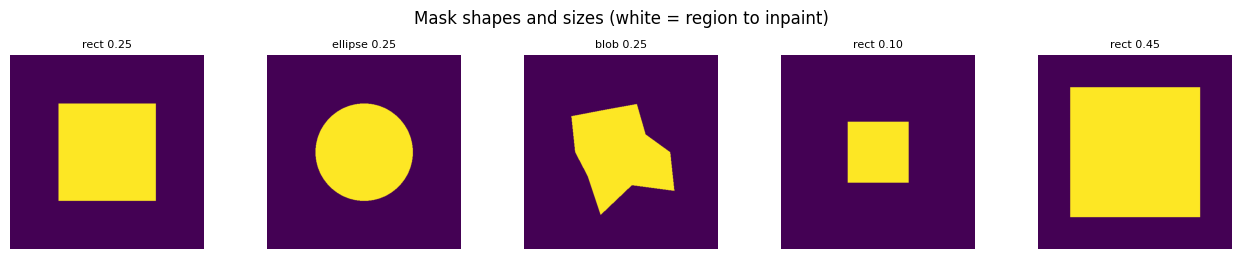

In [5]:
def rect_mask(frac=0.25, center=None):
    m=Image.new("L",(CFG.resolution,)*2,0); d=ImageDraw.Draw(m)
    side=int(CFG.resolution*(frac**0.5)); cx,cy=center or (CFG.resolution//2,)*2
    d.rectangle([cx-side//2,cy-side//2,cx+side//2,cy+side//2], fill=255); return m

def ellipse_mask(frac=0.25, center=None):
    m=Image.new("L",(CFG.resolution,)*2,0); d=ImageDraw.Draw(m)
    r=int(CFG.resolution*(frac**0.5)/2); cx,cy=center or (CFG.resolution//2,)*2
    d.ellipse([cx-r,cy-r,cx+r,cy+r], fill=255); return m

def blob_mask(frac=0.25, center=None, seed=0):
    rng=np.random.default_rng(seed)
    m=Image.new("L",(CFG.resolution,)*2,0); d=ImageDraw.Draw(m)
    cx,cy=center or (CFG.resolution//2,)*2
    base=CFG.resolution*(frac**0.5)/2
    pts=[];
    for a in np.linspace(0,2*np.pi,10,endpoint=False):
        rr=base*(0.6+0.8*rng.random())
        pts.append((cx+rr*np.cos(a), cy+rr*np.sin(a)))
    d.polygon(pts, fill=255); return m

# visualise the mask family
demo=[rect_mask(0.25), ellipse_mask(0.25), blob_mask(0.25,seed=1),
      rect_mask(0.1), rect_mask(0.45)]
grid(demo, titles=["rect 0.25","ellipse 0.25","blob 0.25","rect 0.10","rect 0.45"],
     ncols=5, suptitle="Mask shapes and sizes (white = region to inpaint)", fname="t3_masks.png")

## 5. Inpaint: remove / replace a region (report §7)

Each of the ≥10 images gets a centre mask and a prompt describing new content to synthesise.
We show input | mask overlay | output.

inpaint:   0%|          | 0/10 [00:00<?, ?it/s]

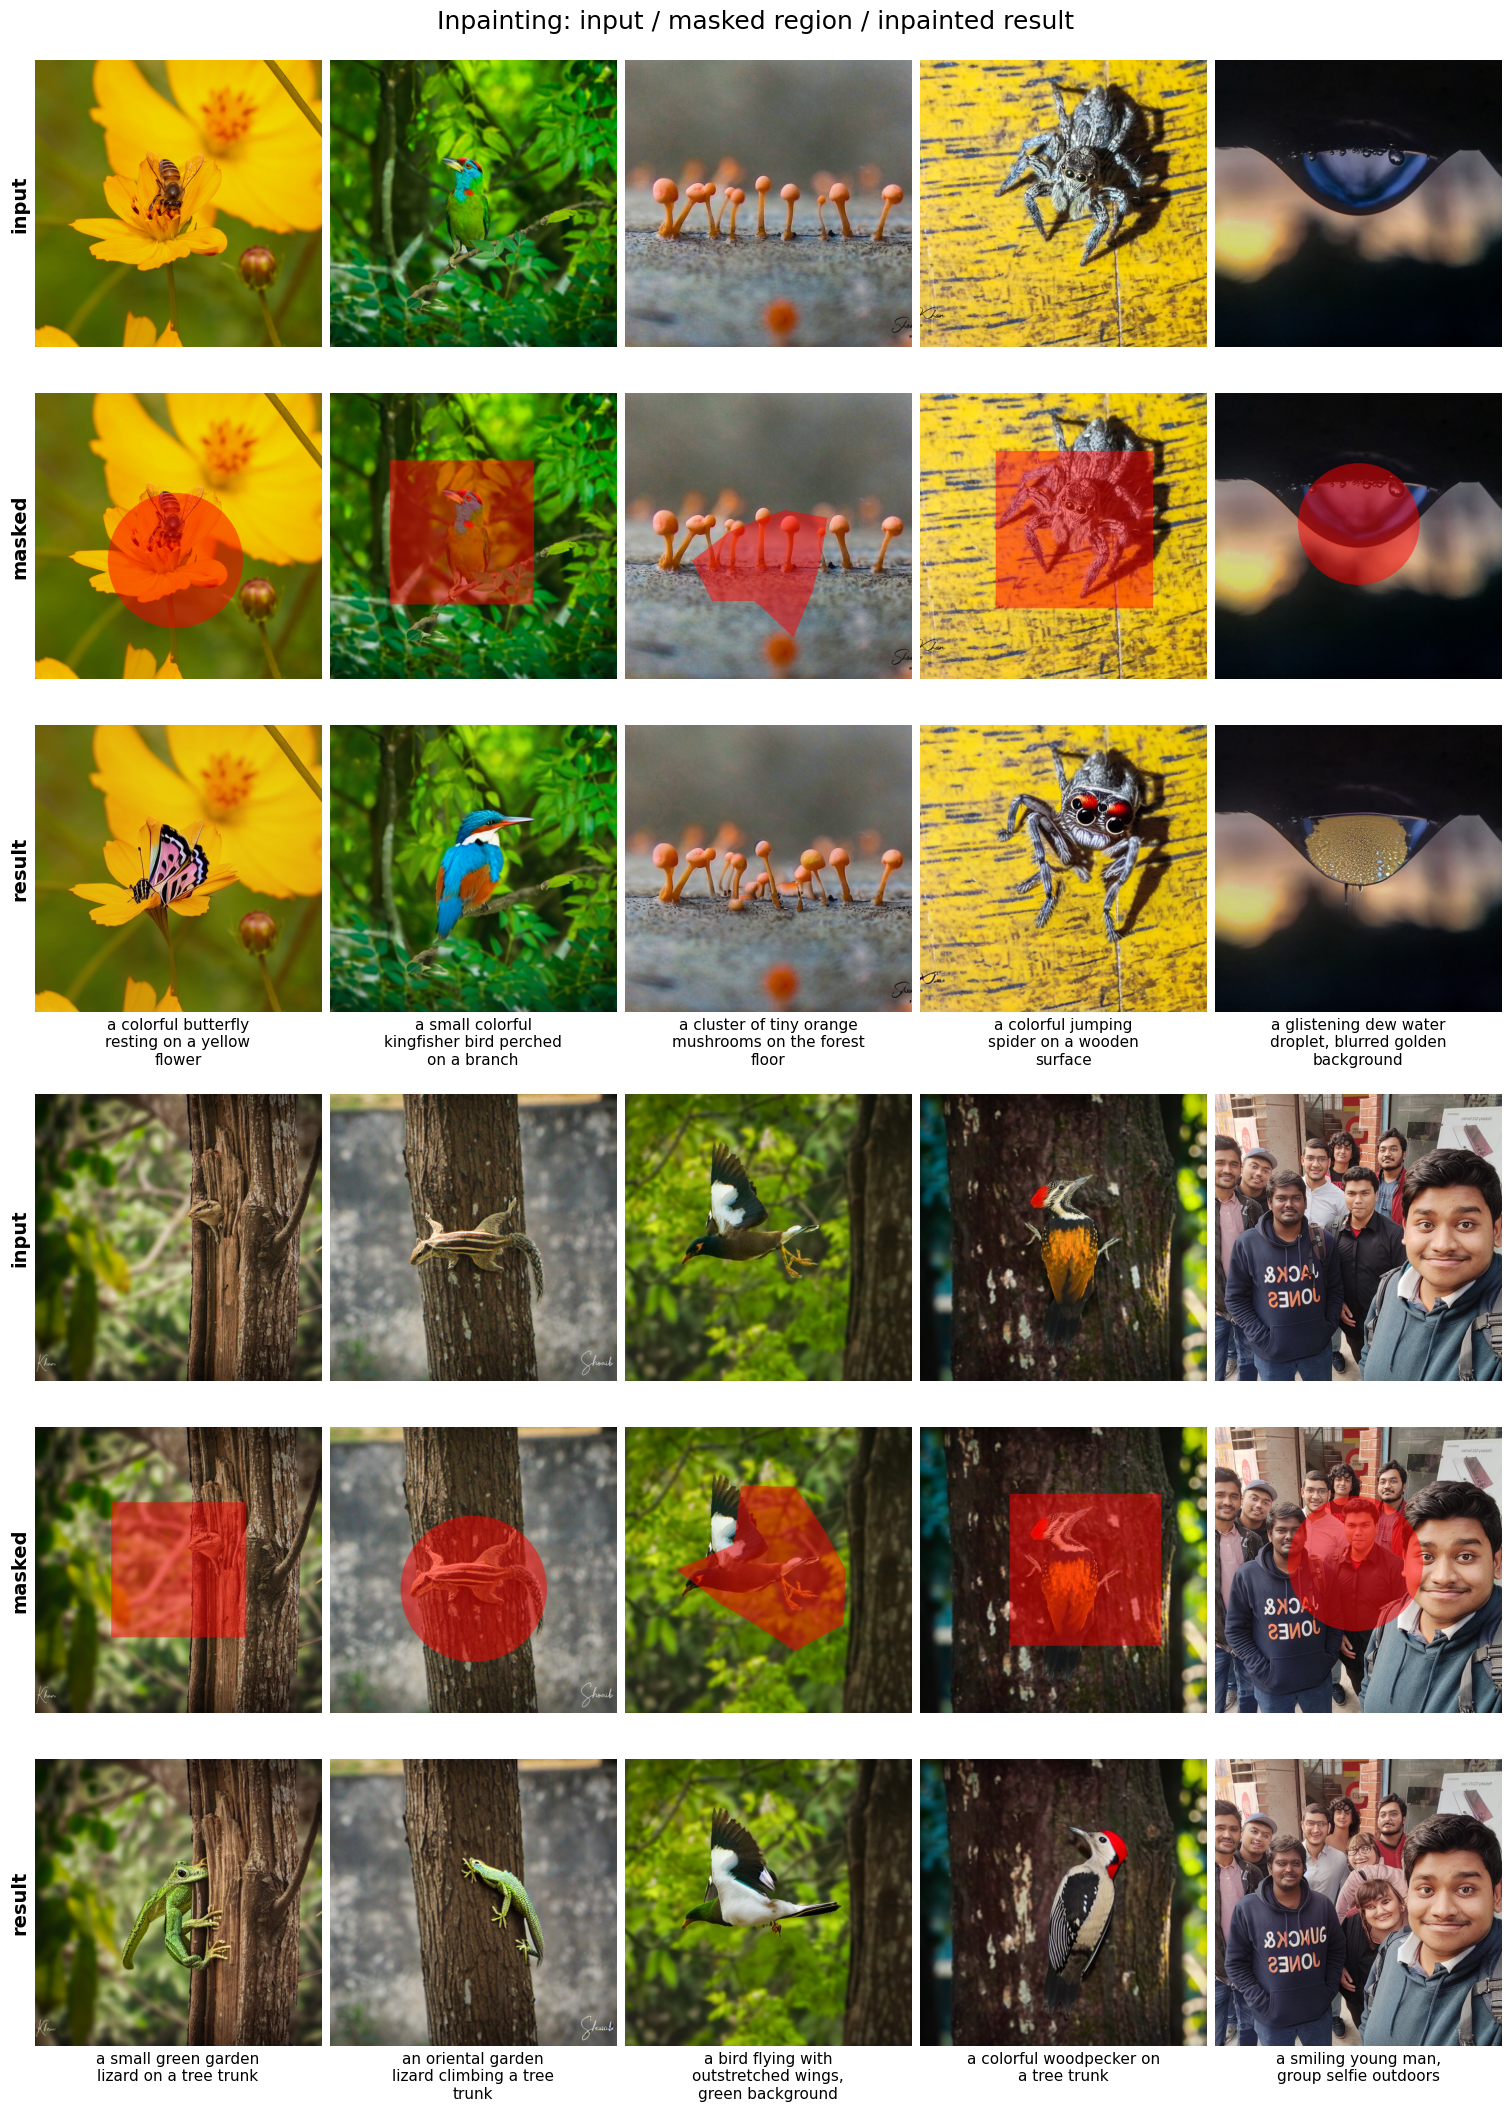

In [6]:
# relatable, scene-appropriate replacement prompts, one per test image (analysed by content)
REPLACE_PROMPTS = [
    "a colorful butterfly resting on a yellow flower",        # 01 bee on yellow flower
    "a small colorful kingfisher bird perched on a branch",   # 02 barbet in green foliage
    "a cluster of tiny orange mushrooms on the forest floor", # 03 mushrooms macro
    "a colorful jumping spider on a wooden surface",          # 04 spider on wood
    "a glistening dew water droplet, blurred golden background",  # 05 water droplet + bokeh
    "a small green garden lizard on a tree trunk",            # 06 lizard on trunk
    "an oriental garden lizard climbing a tree trunk",        # 07 lizard on trunk
    "a bird flying with outstretched wings, green background", # 08 bird in flight
    "a colorful woodpecker on a tree trunk",                  # 09 woodpecker on tree
    "a smiling young man, group selfie outdoors",             # 10 group selfie
]

def inpaint(image, mask, prompt, guidance=None, steps=None, seed=0, negative_prompt=None):
    g=torch.Generator(device=device).manual_seed(seed)
    out=pipe(prompt=prompt, image=image, mask_image=mask,
             guidance_scale=guidance if guidance is not None else CFG.guidance_scale,
             num_inference_steps=steps or CFG.num_inference_steps,
             height=CFG.resolution, width=CFG.resolution,
             negative_prompt=negative_prompt, generator=g)
    return out.images[0]

def overlay(image, mask, alpha=0.5):
    base=image.convert("RGB").copy()
    red=Image.new("RGB", base.size, (255,0,0))
    return Image.composite(Image.blend(base,red,alpha), base, mask)

# variable masks: each image gets a different shape, size (area fraction) and position
MASK_SPECS = [
    ("ellipse", 0.22, (250, 300)),  # 01 flower
    ("rect",    0.25, (235, 250)),  # 02 bird
    ("blob",    0.20, (256, 300)),  # 03 mushrooms
    ("rect",    0.30, (275, 245)),  # 04 spider
    ("ellipse", 0.18, (256, 235)),  # 05 droplet
    ("rect",    0.22, (256, 256)),  # 06 lizard
    ("ellipse", 0.26, (256, 290)),  # 07 lizard
    ("blob",    0.24, (256, 256)),  # 08 bird in flight
    ("rect",    0.28, (295, 256)),  # 09 woodpecker
    ("ellipse", 0.22, (250, 245)),  # 10 selfie
]
def make_mask(shape, frac, center, seed=0):
    if shape == "rect":    return rect_mask(frac, center)
    if shape == "ellipse": return ellipse_mask(frac, center)
    return blob_mask(frac, center, seed=seed)

for i,d in enumerate(inputs):
    shp, fr, ctr = MASK_SPECS[i % len(MASK_SPECS)]
    d["mask"]   = make_mask(shp, fr, ctr, seed=i)
    d["prompt"] = REPLACE_PROMPTS[i % len(REPLACE_PROMPTS)]

outputs=[inpaint(d["image"], d["mask"], d["prompt"], seed=CFG.seed) for d in tqdm(inputs, desc="inpaint")]
for i,im in enumerate(outputs): im.save(GEN/f"inpaint_{i:02d}.png")

# input / masked / result montage: 5 columns per block, 3 rows per block.
# constrained_layout + x/y labels is robust for tall grids (plain axis-off + tight_layout collapses).
import textwrap
def _clean(ax):
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(False)
n=len(inputs); ncols=5; nb=math.ceil(n/ncols)
fig,axes=plt.subplots(3*nb,ncols,figsize=(3.0*ncols,3.5*3*nb),constrained_layout=True)
axes=np.array(axes).reshape(3*nb,ncols)
for i in range(n):
    b=i//ncols; j=i%ncols; r=3*b
    axes[r,j].imshow(inputs[i]["image"]);                              _clean(axes[r,j])
    axes[r+1,j].imshow(overlay(inputs[i]["image"],inputs[i]["mask"])); _clean(axes[r+1,j])
    axes[r+2,j].imshow(outputs[i]);                                    _clean(axes[r+2,j])
    axes[r+2,j].set_xlabel("\n".join(textwrap.wrap(inputs[i]["prompt"],24)), fontsize=11)
for k in range(n, nb*ncols):        # blank any unused columns in the last block
    b=k//ncols; j=k%ncols; r=3*b
    for rr in (r,r+1,r+2): axes[rr,j].axis("off")
for b in range(nb):
    for k,t in enumerate(["input","masked","result"]):
        axes[3*b+k,0].set_ylabel(t, fontsize=14, fontweight="bold")
fig.suptitle("Inpainting: input / masked region / inpainted result", fontsize=18)
fig.savefig(FIG/"t3_inpaint_results.png", dpi=130); plt.show()

## 6. Quantitative evaluation (report §8)

- **CLIP-text (region)** — cosine(prompt, cropped generated region): did the fill match the prompt?
- **Surrounding PSNR** — PSNR between input and output over the **unmasked** pixels: are the
  surroundings preserved (seam consistency)?
- **Reconstruction PSNR/SSIM** — a separate ground-truth track: mask a region and prompt with
  the *original caption* to reconstruct it, then measure PSNR/SSIM to the original.
- **FID** — outputs vs input photos (indicative).

In [7]:
from torchmetrics.multimodal.clip_score import CLIPScore
from torchmetrics.functional import structural_similarity_index_measure as ssim_fn
from torchmetrics.functional import peak_signal_noise_ratio as psnr_fn
from torchmetrics.image.fid import FrechetInceptionDistance

def to_u8(img): return torch.from_numpy(np.array(img.convert("RGB"))).permute(2,0,1).contiguous()
def to_f(img):  return to_u8(img).float()/255.0
clip_metric = CLIPScore(model_name_or_path="openai/clip-vit-base-patch32").to(device)

@torch.no_grad()
def clip_text(img, prompt): return float(clip_metric(to_u8(img).to(device), prompt).cpu())

def surrounding_psnr(inp, out, mask):
    o=np.asarray(out).astype(np.float32)/255; i=np.asarray(inp).astype(np.float32)/255
    m=(np.asarray(mask)>127); keep=~m
    if keep.sum()==0: return float("nan")
    mse=float(((o-i)[keep].__pow__(2)).mean())
    return 99.0 if mse==0 else float(10*np.log10(1.0/mse))

rows=[]
for i,(d,out) in enumerate(zip(inputs,outputs)):
    bbox=d["mask"].getbbox()
    region=out.crop(bbox)
    rows.append({"idx":i,"prompt":d["prompt"],
                 "CLIP_text_region":round(clip_text(region,d["prompt"]),2),
                 "surround_PSNR":round(surrounding_psnr(d["image"],out,d["mask"]),2)})
metrics_df=pd.DataFrame(rows); metrics_df.to_csv(RES_DIR/"per_image_metrics.csv",index=False)

# reconstruction track (ground truth available)
n_recon = 3 if CFG.quick_mode else 5
rec=[]
for d in inputs[:n_recon]:
    m=rect_mask(0.2)
    # prompt = original caption when it is a real sentence, else empty (context-only reconstruction)
    recon_prompt = d["caption"] if len(str(d["caption"]).split()) >= 3 else ""
    out=inpaint(d["image"], m, recon_prompt, seed=CFG.seed)
    a=to_f(out).unsqueeze(0); b=to_f(d["image"]).unsqueeze(0)
    rec.append({"PSNR":float(psnr_fn(a,b)),"SSIM":float(ssim_fn(a,b))})
rec_df=pd.DataFrame(rec)

fid=FrechetInceptionDistance(feature=2048, normalize=True).to(device)
def st(imgs): return torch.stack([to_f(im.resize((299,299))) for im in imgs]).to(device)
fid.update(st([d["image"] for d in inputs][:CFG.n_fid_images]), real=True)
fid.update(st(outputs[:CFG.n_fid_images]), real=False)

summary={"CLIP_text_region_mean":round(metrics_df["CLIP_text_region"].mean(),2),
         "surround_PSNR_mean":round(metrics_df["surround_PSNR"].mean(),2),
         "recon_PSNR_mean":round(rec_df["PSNR"].mean(),2),
         "recon_SSIM_mean":round(rec_df["SSIM"].mean(),3),
         "FID_out_vs_input":round(float(fid.compute().cpu()),2),
         "n_inputs":len(inputs)}
json.dump(summary, open(RES_DIR/"summary_metrics.json","w"), indent=2)
print(json.dumps(summary, indent=2)); metrics_df

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


{
  "CLIP_text_region_mean": 32.24,
  "surround_PSNR_mean": 30.81,
  "recon_PSNR_mean": 29.75,
  "recon_SSIM_mean": 0.763,
  "FID_out_vs_input": 154.12,
  "n_inputs": 10
}


,idx,prompt,CLIP_text_region,surround_PSNR
0,0,a colorful butterfly resting on a yellow flower,32.74,31.73
1,1,a small colorful kingfisher bird perched on a ...,33.51,30.47
2,2,a cluster of tiny orange mushrooms on the fore...,33.05,31.00
3,3,a colorful jumping spider on a wooden surface,33.94,25.60
4,4,"a glistening dew water droplet, blurred golden...",31.66,36.53
5,5,a small green garden lizard on a tree trunk,32.88,26.74
6,6,an oriental garden lizard climbing a tree trunk,30.12,30.51
7,7,"a bird flying with outstretched wings, green b...",35.39,35.82
8,8,a colorful woodpecker on a tree trunk,33.03,34.48
9,9,"a smiling young man, group selfie outdoors",26.06,25.20


## 7. Compare mask sizes and shapes (report §10, required)

The assignment asks explicitly to compare **different mask sizes and shapes**. We fix the
image + prompt and vary each.

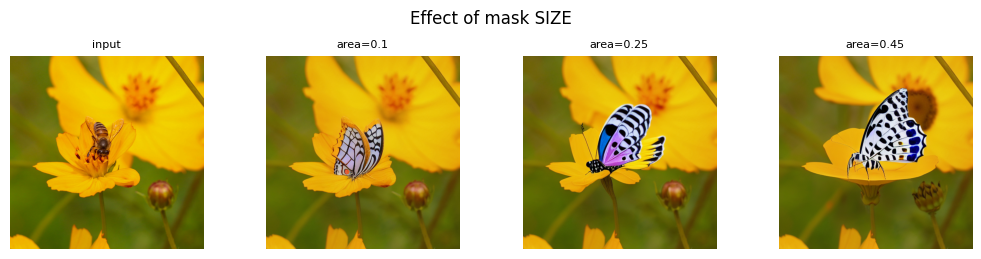

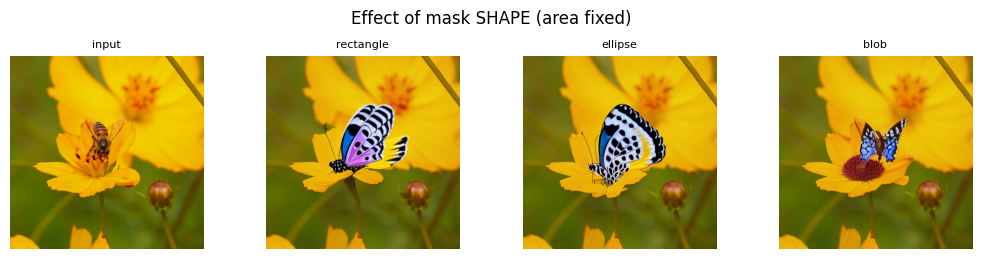

MASK SIZE:
    mask_area  CLIP_text_region  surround_PSNR
0       0.10             33.38          32.12
1       0.25             32.57          32.75
2       0.45             31.99          31.22 

MASK SHAPE:
   mask_shape  CLIP_text_region  surround_PSNR
0  rectangle             32.57          32.75
1    ellipse             32.07          32.76
2       blob             32.37          32.98


In [8]:
img0=inputs[0]["image"]; prm0="a colorful butterfly resting on a yellow flower"

# mask SIZE
sizes=[0.1,0.25,0.45]
imgs=[img0]; labels=["input"]; size_rows=[]
for fr in sizes:
    m=rect_mask(fr); o=inpaint(img0,m,prm0,seed=CFG.seed)
    imgs.append(o); labels.append(f"area={fr}")
    size_rows.append({"mask_area":fr,"CLIP_text_region":round(clip_text(o.crop(m.getbbox()),prm0),2),
                      "surround_PSNR":round(surrounding_psnr(img0,o,m),2)})
grid(imgs, titles=labels, ncols=len(imgs), fs=2.6, suptitle="Effect of mask SIZE", fname="t3_mask_size.png")

# mask SHAPE (fixed area)
shapes={"rectangle":rect_mask(0.25),"ellipse":ellipse_mask(0.25),"blob":blob_mask(0.25,seed=2)}
imgs=[img0]; labels=["input"]; shape_rows=[]
for nm,m in shapes.items():
    o=inpaint(img0,m,prm0,seed=CFG.seed)
    imgs.append(o); labels.append(nm)
    shape_rows.append({"mask_shape":nm,"CLIP_text_region":round(clip_text(o.crop(m.getbbox()),prm0),2),
                       "surround_PSNR":round(surrounding_psnr(img0,o,m),2)})
grid(imgs, titles=labels, ncols=len(imgs), fs=2.6, suptitle="Effect of mask SHAPE (area fixed)", fname="t3_mask_shape.png")

size_df=pd.DataFrame(size_rows); shape_df=pd.DataFrame(shape_rows)
size_df.to_csv(RES_DIR/"mask_size.csv",index=False); shape_df.to_csv(RES_DIR/"mask_shape.csv",index=False)
print("MASK SIZE:\n", size_df, "\n\nMASK SHAPE:\n", shape_df)

## 8. Guidance and steps (report §10)

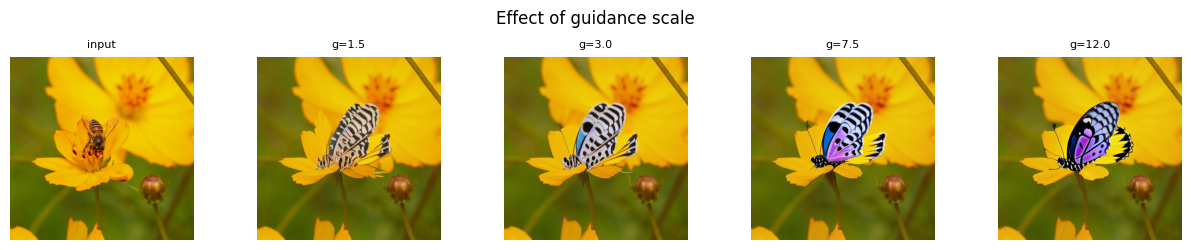

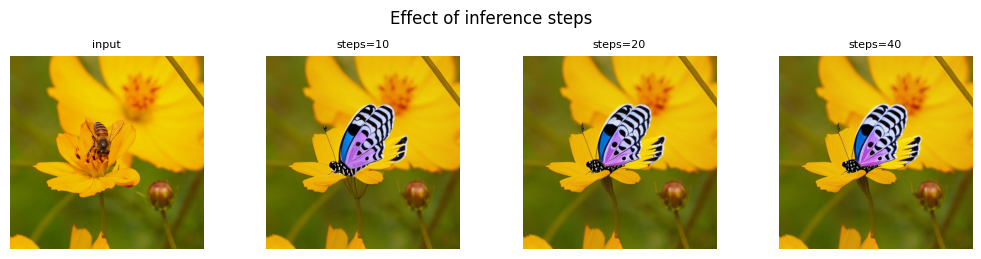

In [9]:
m=rect_mask(0.25)
imgs=[img0]; labels=["input"]
for gv in [1.5,3.0,7.5,12.0]:
    imgs.append(inpaint(img0,m,prm0,guidance=gv,seed=CFG.seed)); labels.append(f"g={gv}")
grid(imgs, titles=labels, ncols=len(imgs), fs=2.5, suptitle="Effect of guidance scale", fname="t3_guidance.png")

imgs=[img0]; labels=["input"]
for sv in [10,20,40]:
    imgs.append(inpaint(img0,m,prm0,steps=sv,seed=CFG.seed)); labels.append(f"steps={sv}")
grid(imgs, titles=labels, ncols=len(imgs), fs=2.6, suptitle="Effect of inference steps", fname="t3_steps.png")

## 9. Discussion (report §11–§14)

**System.** SD-1.5 inpainting: the masked image and mask are concatenated to a 9-channel UNet,
so the model regenerates only the masked pixels under the prompt while the unmasked pixels are
carried through. All weights frozen — inference only.

**Mask size and shape (the required comparison).** Larger masks give the model more freedom, so
prompt adherence in the region tends to rise, but the seam gets harder and surrounding
consistency is more fragile; very small masks constrain the fill and can look pasted. Shape
matters less than size at equal area — rectangles, ellipses and irregular blobs give similar
metrics — but soft/irregular boundaries usually blend more naturally than a hard rectangle.

**Consistency.** Surrounding-PSNR is high because inpainting preserves unmasked pixels by
construction (only a slight VAE re-encode drift). The reconstruction track (prompt = original
caption) is the honest ground-truth check: PSNR/SSIM there measure how faithfully the model can
put back plausible content.

**Limitations.** Single seed; geometric (not object-segmentation) masks; SD-1.5 inpainting can
leave boundary artefacts on large masks and struggles with exact object counts.

**Bridge (the "Important Question").**

| Task | `x` | `y` | UNet input |
|---|---|---|---|
| Text-to-image | text | image | 4-ch |
| Image-to-image | text + input (noised init) | edited image | 4-ch |
| **Inpainting (this task)** | **text + image + mask** | filled image | **9-ch (latent+masked-image+mask)** |
| Outpainting | text + image + border mask | extended image | 9-ch |

Inpainting is the first task that needs a **different UNet** — the mask conditioning cannot be
expressed by initialisation alone. Figures/tables are under `outputs_task3/`.